# Chapter 9: Dimensionality reduction

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.mlab as mlab
import seaborn as sns; sns.set()
from scipy import stats
import math
import os
import random
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.decomposition import PCA

## 9.1 Introduction & Motivation

We've seen quite a few regression, classification and clustering methods. That's great! We can already train a lot of different models and gain insights from them. However, now it's time to take a small step back and look at the data we are feeding our models. Instead of just throwing everything we have at it, we are going to reduce our data by performing **PCA**.

Why do we do this? When working with large dataset, training a model becomes more complex. For example, think of the training process of a GPT model. The more data is being used, the more time it will take to train and the more CPU power it will use, requiring expensive machinery and also driving up the electricity bill like crazy. We do however want to retain most of the information contained in our data. That's where PCA comes into play. We reduce data by reshaping it to a few core components and keeping the information contained within.

## 9.2 Problem setting

The faces dataset is a usefull dataset when exploring the differences between models and the effect of dimensionality reduction techniques. This makes it a prime candidate to explore PCA!

Similar to the digits datast, it contains a bunch of images and labels. This time however, the images are not handwritten digits but faces of famous American politicians. Try to explore the dataset and find out what we can achieve with PCA!

## 9.3 Model

First, let's have a look at the data.

In [2]:
from sklearn.datasets import fetch_lfw_people
faces = fetch_lfw_people(min_faces_per_person=60)
print(faces.target_names)
print(faces.images.shape)

['Ariel Sharon' 'Colin Powell' 'Donald Rumsfeld' 'George W Bush'
 'Gerhard Schroeder' 'Hugo Chavez' 'Junichiro Koizumi' 'Tony Blair']
(1348, 62, 47)


#### Question 1: By now you should be familiar with the digits dataset. Visualize the faces dataset in a similar way. Show only the first 5 faces. Can you display the correct name as labels?

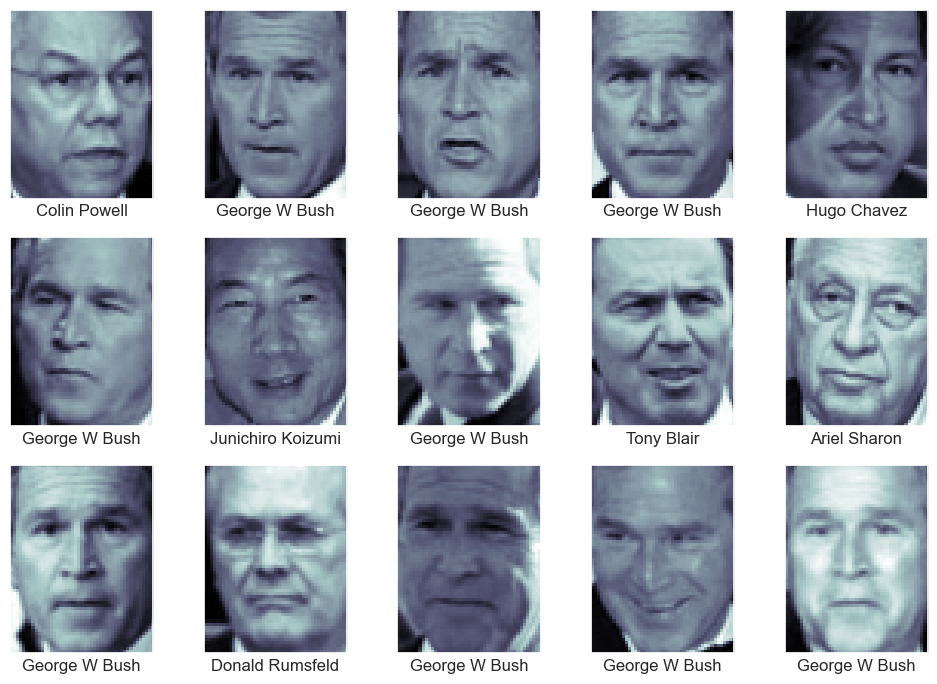

In [3]:
fig, ax = plt.subplots(3, 5, figsize=(10, 7))

# Iterate through the axes and plot images
for i, axi in enumerate(ax.flat):
    # faces.images[i] contains the pixel data
    axi.imshow(faces.images[i], cmap='bone')
    axi.set(xticks=[], yticks=[], xlabel=faces.target_names[faces.target[i]])

plt.tight_layout()
plt.show()

#### Question 2: Train a classification method of your choice to get some predictions. Use cross-validation to get the best results. Remember to select the best parameters!

In [5]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score

Tree = DecisionTreeClassifier(random_state=42)

X = faces.data
y = faces.target

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42, test_size=0.25)

Tree.fit(X_train, y_train)

y_pred = Tree.predict(X_test)

scores = cross_val_score(Tree, X, y, cv=10)
print(f"All Scores: {scores}")
print(f"Mean Accuracy: {scores.mean():.2%}")
print(f"Standard Deviation: {scores.std():.2%}")

All Scores: [0.45185185 0.48888889 0.44444444 0.42222222 0.45185185 0.2962963
 0.42222222 0.51851852 0.50746269 0.47761194]
Mean Accuracy: 44.81%
Standard Deviation: 5.95%


In [6]:
faces.data # => 2D array. For each array: contains numbers from 0 to 1 (0 to 255) that represent brightness of that specific pixel.

array([[0.53333336, 0.52418303, 0.49673203, ..., 0.00653595, 0.00653595,
        0.00130719],
       [0.28627452, 0.20784314, 0.2535948 , ..., 0.96993464, 0.95032686,
        0.9346406 ],
       [0.31633988, 0.3895425 , 0.275817  , ..., 0.4261438 , 0.7895425 ,
        0.9555555 ],
       ...,
       [0.11633987, 0.11111111, 0.10196079, ..., 0.5660131 , 0.579085  ,
        0.5542484 ],
       [0.19346406, 0.21045752, 0.29150328, ..., 0.6875817 , 0.6575164 ,
        0.5908497 ],
       [0.12418301, 0.09673203, 0.10849673, ..., 0.12941177, 0.16209151,
        0.29150328]], dtype=float32)

## 9.4 Model Evaluation

#### Question 3: It's time to reduce our data using PCA! figure out the best amount of principal components and reduce the data.

**Hint: Remember to properly scale your data first!**

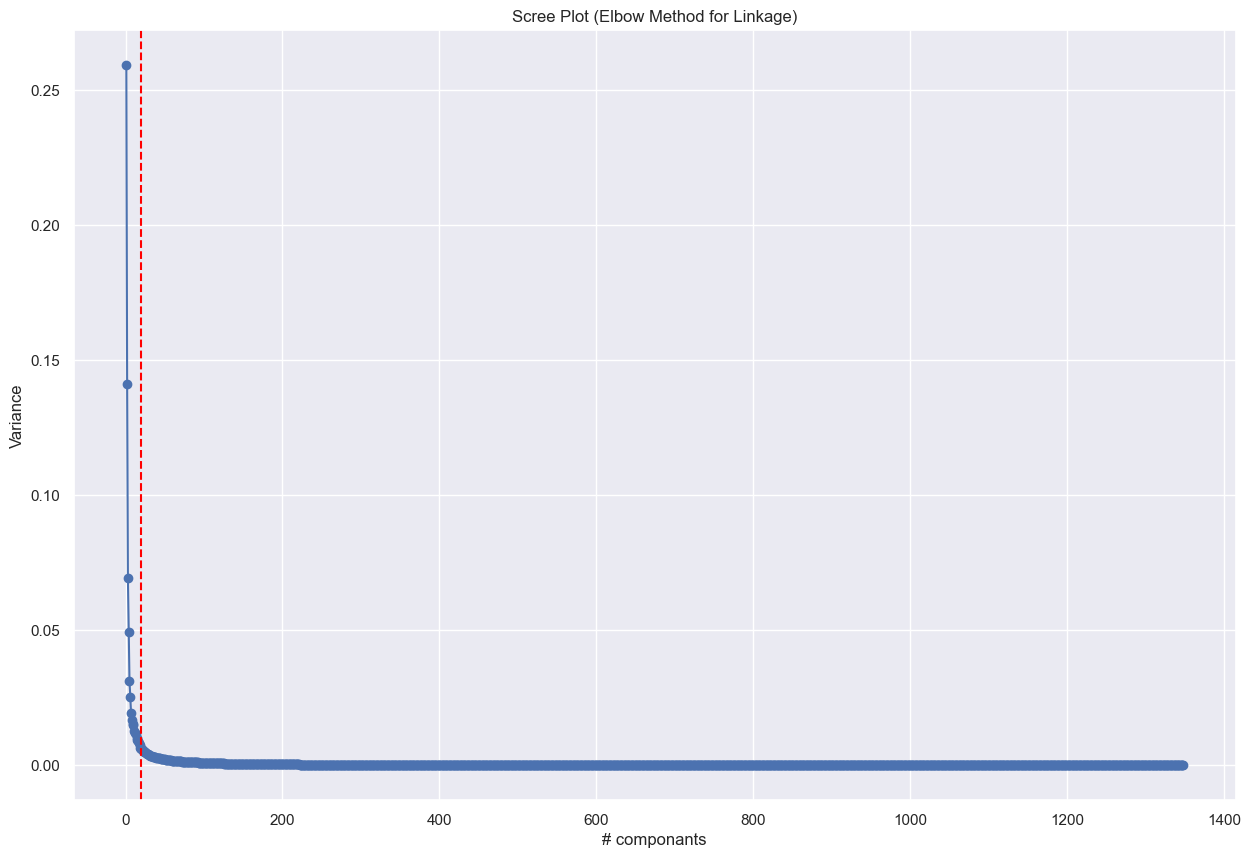

In [6]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(faces.data)

pca = PCA().fit(X_scaled)

last = pca.explained_variance_ratio_
idxs = np.arange(1, len(last) + 1)

plt.figure(figsize=(15,10))
plt.plot(idxs, last, marker='o')
plt.axvline(x=20, color='red', linestyle='--')
plt.title('Scree Plot (Elbow Method for Linkage)')
plt.xlabel('# componants')
plt.ylabel('Variance')
plt.show()

Best amount of componants: 15-20

In [69]:
last[:20].sum()

0.7343989

In [67]:
last[:20]

array([0.25923482, 0.14127101, 0.06924999, 0.0492464 , 0.03129382,
       0.02535506, 0.01942821, 0.01662645, 0.01522315, 0.01483173,
       0.01258586, 0.01205501, 0.0115986 , 0.00995851, 0.00920005,
       0.00896723, 0.00833975, 0.00735012, 0.00643991, 0.00614316],
      dtype=float32)

#### Question 4: Do you notice something special about the eigenvalues? What is the total sum of all eigenvalues? Play around with models with different amount of components. How does this change? Is this expected? Elaborate based on the meaning of eigenvalue.

Something special about the eigenvalues: they decay extremely fast in variance. The difference in variance between the first and the fifth component is extremely high. This could be because there are a lot of pixels that don't change significantly in brightness: leading to low variance.

Therefore, the total sum of the eigenvalues (with 20 components, a coverage of 73% of variance) are mostly made up by the first few components (with the highest variance). The others add almost no variance, meaning they are essentialy pointless.

Testing model with 5, 50, 100, 150 and 200 components

In [7]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(faces.data)

pca5 = PCA(5)
pca50 = PCA(50)
pca100 = PCA(100)
pca150 = PCA(150)
pca200 = PCA(200)

pcadict = {
    "pca5": pca5,
    "pca50": pca50,
    "pca100": pca100,
    "pca150": pca150,
    "pca200": pca200,
}

evaluations = {
    "pca5": [],
    "pca50": [],
    "pca100": [],
    "pca150": [],
    "pca200": [],
}

for i in pcadict.keys():
    currentpca = pcadict[i]
    projected = currentpca.fit_transform(X_scaled)

    X = projected
    y = faces.target

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

    tree = DecisionTreeClassifier()
    tree.fit(X_train, y_train)

    y_pred = tree.predict(X_test)
    scores = cross_val_score(Tree, X, y, cv=10)

    evaluations[i].append(scores.mean())
    evaluations[i].append(scores.std())

for i in evaluations.keys():
    print(i, f"Accuracy: {evaluations[i][0]}", f"Stdv: {evaluations[i][1]}")

pca5 Accuracy: 0.27232725262576013 Stdv: 0.04628185182617814
pca50 Accuracy: 0.46662244333886116 Stdv: 0.03744015334934516
pca100 Accuracy: 0.4510503040353787 Stdv: 0.03668197129118033
pca150 Accuracy: 0.4450967385295743 Stdv: 0.03250653187845115
pca200 Accuracy: 0.45252072968490886 Stdv: 0.018359414037973858


In [27]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

X = faces.data
y = faces.target

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42, test_size=0.25)

scaler = StandardScaler()
pca = PCA(n_components=50)
model = KNeighborsClassifier(n_neighbors=5)

TrainX_Scale = scaler.fit_transform(X_train)
TrainX_pca = pca.fit_transform(TrainX_Scale)

model.fit(TrainX_pca, y_train)

TestX_Scale = scaler.transform(X_test)
TestX_pca = pca.transform(TestX_Scale)

ypred = model.predict(TestX_pca)

print(accuracy_score(y_test, ypred))

0.5519287833827893


### Conclusion

Despite the elbow method showing that the best number of componants is at 15-20 (highest variance), this results in a severly low accuracy.

This makes sense, since you are essentially tasking a model with describing a face with only 15-20 features. 

However, when the amount of components is increased: so does the accuracy. Showing that despite what the elbow method told us, taking a bit more components (in this case 50) is better for a higher accuracy score. Any more beyond 50 is pure noise, which is obvious from the extremely low variance.

#### Question 5: Use PCA and the best amount of components you found earlier to reduce your data. Retrain your model using kfold and compare the accuracy. What do you notice?

In [73]:
X_scaled = scaler.fit_transform(faces.data)

pca50 = PCA(50)
projected = pca50.fit_transform(X_scaled)

X = projected
y = faces.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

tree = DecisionTreeClassifier()
tree.fit(X_train, y_train)

y_pred = tree.predict(X_test)

scores = cross_val_score(tree, X, y, cv=10)
#modelscores = cross_val_score(model, X, y, cv=10)

print(f"All Scores: {scores}")
print(f"Mean Accuracy: {scores.mean():.2%}")
print(f"Standard Deviation: {scores.std():.2%}")

All Scores: [0.40740741 0.47407407 0.44444444 0.45185185 0.48888889 0.42962963
 0.51111111 0.5037037  0.47761194 0.53731343]
Mean Accuracy: 47.26%
Standard Deviation: 3.78%


Surprisingly, applying PCA with 50 components increased accuracy from 44.81% to 47.26%.

The first model used no PCA, which resulted in an accuracy score of 44.81%. 

This makes sense: since the first model (without PCA) included every single variable, even those with the smallest variance. That amount of noise at least partially reduced accuracy. Our model with PCA also still includes noise, but much much less. Which is why the accuracy increases.

The reason the accuracy increases so little, is because the there never really was much more accuracy to gain. As we discussed earlier: the decay of variance is immens. Including all or just a few variables therefore is not going to increase accuracy that much.

#### Question 6: Your department just got granted some extra budget. You are able to use some more processing power, but still not enough to use the entire dataset. Your boss wants you to create a model that contains 90% of all variance. Create this model and calculate the accuracy as before. By how much did you reduce the size of your dataset?

In [8]:
X_scaled = scaler.fit_transform(faces.data)

pca50 = PCA(n_components=0.90)
projected = pca50.fit_transform(X_scaled)

X = projected
y = faces.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

tree = DecisionTreeClassifier()
tree.fit(X_train, y_train)

y_pred = tree.predict(X_test)

scores = cross_val_score(tree, X, y, cv=10)
#modelscores = cross_val_score(model, X, y, cv=10)

print(f"All Scores: {scores}")
print(f"Mean Accuracy: {scores.mean():.2%}")
print(f"Standard Deviation: {scores.std():.2%}")

All Scores: [0.4        0.51111111 0.42222222 0.4        0.45925926 0.45925926
 0.45925926 0.45925926 0.45522388 0.46268657]
Mean Accuracy: 44.88%
Standard Deviation: 3.17%


As you can see, by including more variance than the previous model; it lowered the accuracy by around 3%.

This is because a lot of data contributes almost nothing to the variance. By introducing this massive amount of noise, a model's decision-making gets obscured

## 9.5 Exercises

#### Question 1: See section 9.3
#### Question 2: See section 9.3
#### Question 3: See section 9.4
#### Question 4: See section 9.4
#### Question 5: See section 9.4
#### Question 6: See section 9.4
#### Question 7: PCA is used to reduce the amount of variables by creating new variables which explain multiple previous ones. By definition, you should get somewhat usable results when reversing this process. Transform your prejected data from question 6 back into the original amount of dimensions and compare the data by looking at the the datapoints of the first face.

In [38]:
X_reconstructed_scaled = pca50.inverse_transform(projected)
X_reconstructed = scaler.inverse_transform(X_reconstructed_scaled)
X_original = faces.data

In [39]:
print("original pixels:", X_original[:5])
print("reconstructed pixels", X_reconstructed[:5])

original pixels: [[0.53333336 0.52418303 0.49673203 ... 0.00653595 0.00653595 0.00130719]
 [0.28627452 0.20784314 0.2535948  ... 0.96993464 0.95032686 0.9346406 ]
 [0.31633988 0.3895425  0.275817   ... 0.4261438  0.7895425  0.9555555 ]
 [0.25882354 0.30718955 0.48366013 ... 0.90326804 0.8849673  0.8       ]
 [0.22222222 0.22091503 0.18562092 ... 0.13594772 0.14117648 0.13333334]]
reconstructed pixels [[ 0.5230147   0.52923924  0.5147692  ...  0.01767149  0.00281108
  -0.02621413]
 [ 0.23555315  0.26470748  0.28487805 ...  1.0113323   0.9177535
   0.82274514]
 [ 0.35952348  0.36376438  0.34502685 ...  0.55876005  0.59152
   0.5852936 ]
 [ 0.35922697  0.3627868   0.37991846 ...  0.96340525  0.87730074
   0.75345916]
 [ 0.18572533  0.21079415  0.2258392  ...  0.11750895  0.19256319
   0.25889534]]


#### Question 8: Now that you have figured out the process of reversing PCA, visualize the reversed data. Compare the reconstructed faces with the original ones and behold the true power of PCA!

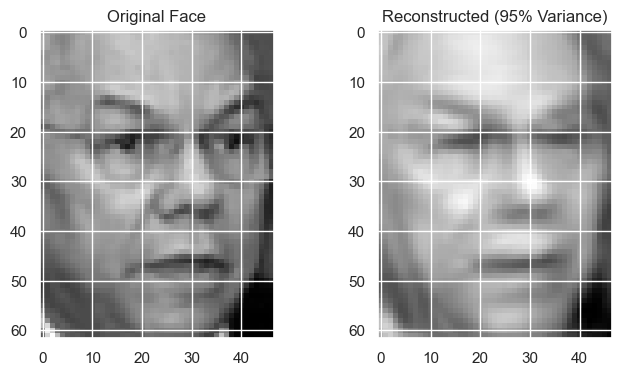

In [40]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(8, 4))

ax[0].imshow(X_original[0].reshape(faces.images[0].shape), cmap='gray')
ax[0].set_title("Original Face")

ax[1].imshow(X_reconstructed[0].reshape(faces.images[0].shape), cmap='gray')
ax[1].set_title("Reconstructed (95% Variance)")

plt.show()

From the reconstruction, it is a bit harder to define the face than in the original despite taking into account 95% of the variance.

(ps: DO NOT LOWER THE VARIANCE TO 20%, YOU WILL GET JUMPSCARED)

#### Question 9: We talked briefly about how PCA can be used to reduce noise. Assume the 'noisy' data as seen below. Plot the faces as you did before to visually see the noise. What's the best result you can achieve when using PCA to reduce the noise?

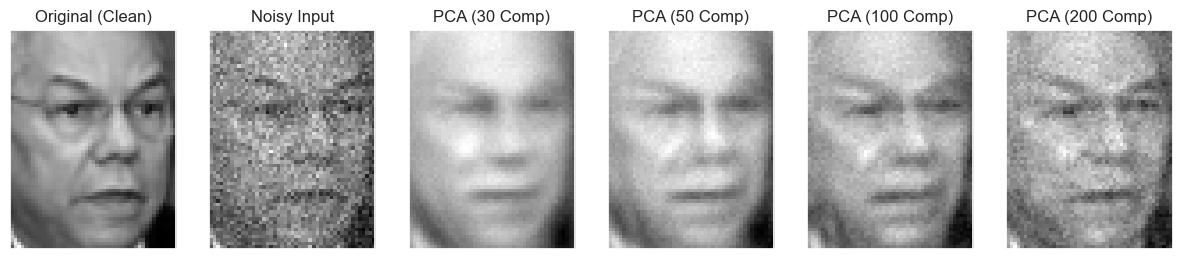

In [ ]:
np.random.seed(42)
noisy = np.random.normal(faces.data, 0.1)

components_to_try = [30, 50, 100, 200]
fig, axes = plt.subplots(1, 6, figsize=(15, 4), subplot_kw={'xticks':[], 'yticks':[]})

axes[0].imshow(faces.data[0].reshape(62, 47), cmap='gray')
axes[0].set_title("Original (Clean)")

axes[1].imshow(noisy[0].reshape(62, 47), cmap='gray')
axes[1].set_title("Noisy Input")

for i, n in enumerate(components_to_try):
    pca = PCA(n_components=n).fit(noisy)
    components = pca.transform(noisy)
    filtered = pca.inverse_transform(components)
    
    axes[i+2].imshow(filtered[0].reshape(62, 47), cmap='gray')
    axes[i+2].set_title(f"PCA ({n} Comp)")

plt.show()

# Exam

In [4]:
from sklearn.datasets import fetch_lfw_people
faces = fetch_lfw_people(min_faces_per_person=60)
print(faces.target_names)

['Ariel Sharon' 'Colin Powell' 'Donald Rumsfeld' 'George W Bush'
 'Gerhard Schroeder' 'Hugo Chavez' 'Junichiro Koizumi' 'Tony Blair']


In [6]:
print(faces.images.shape)

(1348, 62, 47)


In [ ]:
[[X, Y, Z], [A, B, C], ...]

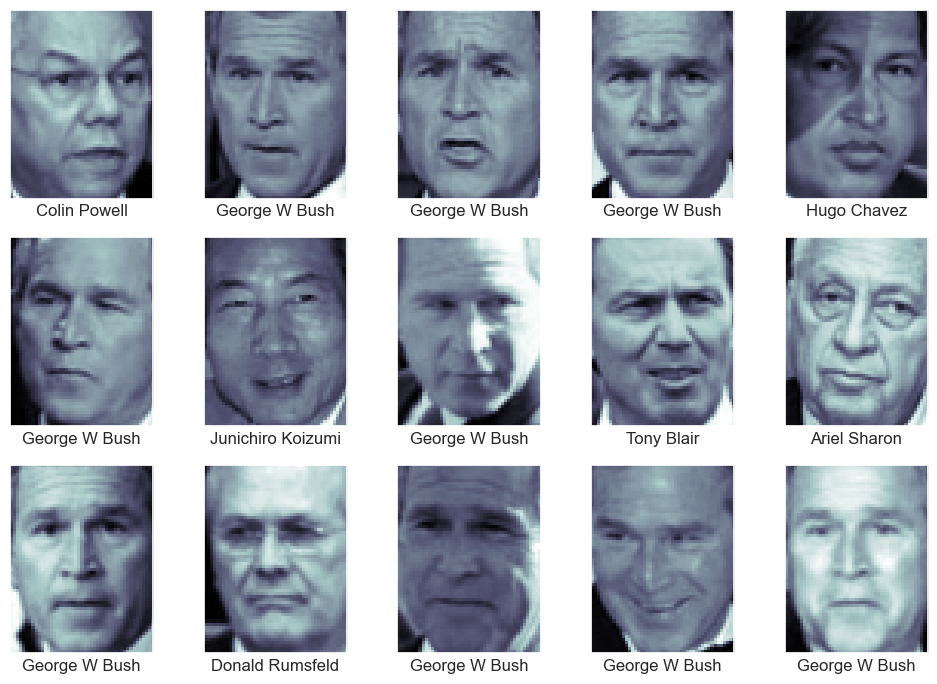

In [8]:
fig, ax = plt.subplots(3, 5, figsize=(10, 7))
for i, axi in enumerate(ax.flat):
    axi.imshow(faces.images[i], cmap="bone")
    axi.set(xticks=[], yticks=[], xlabel=faces.target_names[faces.target[i]])

plt.tight_layout()
plt.show()

In [16]:
print(faces.target_names)

['Ariel Sharon' 'Colin Powell' 'Donald Rumsfeld' 'George W Bush'
 'Gerhard Schroeder' 'Hugo Chavez' 'Junichiro Koizumi' 'Tony Blair']


In [14]:
from sklearn.model_selection import cross_val_score
from sklearn.metrics import accuracy_score
from sklearn.tree import DecisionTreeClassifier

X = faces.data
y = faces.target

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42, test_size=0.25)

Tree = DecisionTreeClassifier(max_depth=150)
Tree.fit(X, y)

ypred = Tree.predict(X_test)

scores = cross_val_score(Tree, X, y, cv=10)
print(f"{scores.mean():.2%}")

45.03%


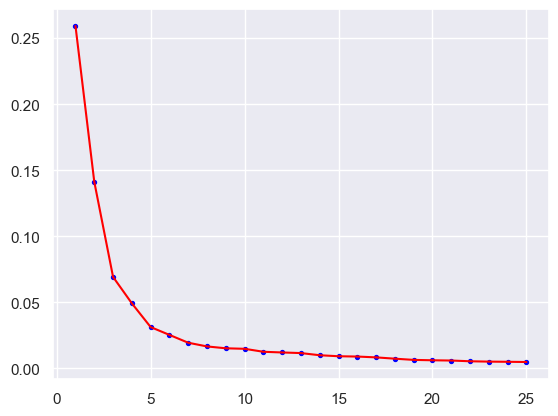

In [27]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
Xscaled = scaler.fit_transform(faces.data)

pca = PCA().fit(Xscaled)

last = pca.explained_variance_ratio_
idxs = np.arange(1, len(last)+1)

plt.plot(idxs[:25], last[:25], color="red")
plt.scatter(idxs[:25], last[:25], color="blue", s=8)